# Immuno Compass · Notebook 10: Fair comparison of all models (Day 13)

**Goal:** put every model side by side on **exactly the same 5 grouped folds** (unseen drugs) and answer:
1. Which model predicts ADA frequency best for a new drug?
2. Is the winner's margin bigger than the fold-to-fold noise?
3. Are the predicted probabilities **calibrated**, and are the uncertainty ranges **honest**?

This notebook does **no new model fitting** except a tiny intercept-only Beta-Binomial baseline. It reads the per-fold scores
and out-of-fold predictions saved in `results/` by notebooks 04–09.

> 🧒 *Simple version:* it's race day. Every runner ran the same track; now we read the stopwatches carefully and check
> whether the winner really won or just got lucky on one lap.

In [1]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [2]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import betabinom, binom
from scipy.optimize import minimize
from scipy.special import expit
np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning)

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped"]])
RES = ROOT / "results"

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

MODELS = {  # key in results/ -> label
    "naive": "Naive baseline",
    "glm_plain": "GLM (plain)",
    "glm_l2": "GLM + L2",
    "glm_l1": "GLM + L1",
    "xgb_default": "XGBoost (plan settings)",
    "xgb": "XGBoost (tuned)",
    "bayes_binomial": "Bayesian Binomial",
    "bayes_betabinomial": "Bayesian Beta-Binomial",
}
SEQ_MODELS = {"glm_l2_seq": "GLM + L2 + sequence", "xgb_default_seq": "XGBoost + sequence",
              "bayes_betabinomial_seq": "Beta-Binomial + sequence"}

## 1 · The scoreboard (mean ± SD over 5 unseen-drug folds)

In [3]:
cv = pd.concat([pd.read_csv(RES / f"cv_{k}.csv") for k in list(MODELS) + list(SEQ_MODELS)])
board = cv.groupby("model")[["wMAE", "wRMSE", "loglik"]].agg(["mean", "std"])
board = board.reindex(list(MODELS) + list(SEQ_MODELS)); board.index = [{**MODELS, **SEQ_MODELS}[k] for k in board.index]
display(board.style.format("{:.3f}").highlight_min(subset=[("wMAE", "mean"), ("wRMSE", "mean")], color="#e6f4ea")
          .highlight_max(subset=[("loglik", "mean")], color="#e6f4ea"))

## 2 · Is any model really better than "guess the average"?

With only 5 folds we can't run a meaningful significance test. Instead we look at **paired per-fold differences** vs the
naive baseline: the average gain, its fold SD, and in how many folds the model wins. A gain smaller than its fold SD, or a
win in only 3/5 folds, is **not convincing**.

In [4]:
base = cv[cv.model == "naive"].set_index("fold")
rows = []
for k, label in {**MODELS, **SEQ_MODELS}.items():
    if k == "naive": continue
    m = cv[cv.model == k].set_index("fold")
    r = {"model": label}
    for metric, better in [("wMAE", "lower"), ("wRMSE", "lower"), ("loglik", "higher")]:
        d = (m[metric] - base[metric]) * (1 if better == "higher" else -1)       # positive = better than naive
        r[f"{metric} gain"] = d.mean(); r[f"{metric} gain SD"] = d.std(); r[f"{metric} wins"] = f"{int((d > 0).sum())}/5"
    rows.append(r)
gains = pd.DataFrame(rows)
display(gains.style.format({c: "{:+.4f}" for c in gains.columns if c.endswith("gain")} |
                           {c: "{:.4f}" for c in gains.columns if c.endswith("SD")}).hide(axis="index"))

model,wMAE gain,wMAE gain SD,wMAE wins,wRMSE gain,wRMSE gain SD,wRMSE wins,loglik gain,loglik gain SD,loglik wins
GLM (plain),-0.0300,0.0240,0/5,-0.0465,0.0403,0/5,-15.5961,12.4434,0/5
GLM + L2,-0.0008,0.0078,3/5,+0.0005,0.0122,2/5,-0.8499,3.0284,3/5
GLM + L1,-0.0037,0.0088,1/5,-0.0045,0.0089,0/5,-1.1417,2.6041,1/5
XGBoost (plan settings),+0.0033,0.0050,4/5,+0.0026,0.0106,2/5,-1.9496,4.0267,1/5
XGBoost (tuned),-0.0047,0.0184,3/5,-0.0029,0.0205,1/5,-3.0416,4.5400,2/5
Bayesian Binomial,-0.0289,0.0240,0/5,-0.0429,0.0405,0/5,-11.4929,7.9383,0/5
Bayesian Beta-Binomial,-0.0274,0.0202,0/5,-0.0258,0.0288,0/5,-3.8145,3.1228,0/5
GLM + L2 + sequence,+0.0022,0.0089,4/5,+0.0010,0.0124,3/5,-1.3443,3.5680,3/5
XGBoost + sequence,+0.0161,0.0203,3/5,+0.0063,0.0208,3/5,-2.0971,6.3392,2/5
Beta-Binomial + sequence,-0.0247,0.0259,0/5,-0.0247,0.0332,1/5,-3.9507,4.0806,1/5


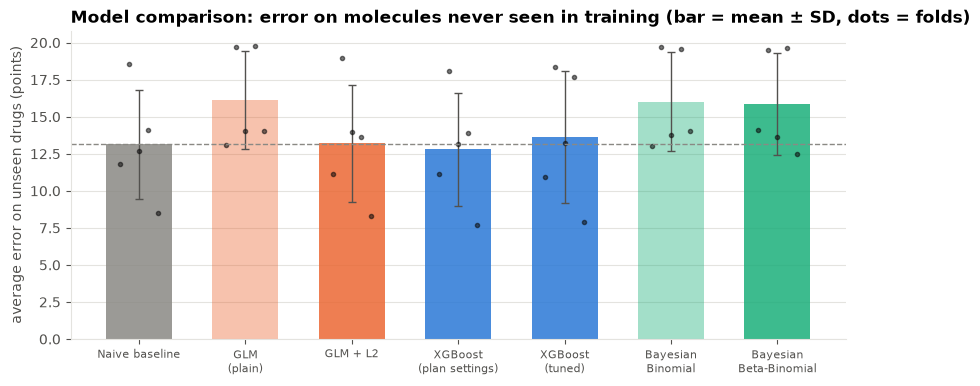

In [5]:
order = ["naive", "glm_plain", "glm_l2", "xgb_default", "xgb", "bayes_binomial", "bayes_betabinomial"]
colors = {"naive": GRAY, "glm_plain": ORANGE, "glm_l2": ORANGE, "xgb_default": BLUE, "xgb": BLUE,
          "bayes_binomial": AQUA, "bayes_betabinomial": AQUA}
fig, ax = plt.subplots(figsize=(10, 4))
for i, k in enumerate(order):
    v = cv[cv.model == k]["wMAE"] * 100
    ax.bar(i, v.mean(), 0.62, color=colors[k], alpha=0.85 if k not in ("glm_plain", "bayes_binomial") else 0.4,
           yerr=v.std(), error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    ax.plot(np.full(5, i) + np.linspace(-0.18, 0.18, 5), v, "o", color="#0b0b0b", ms=3, alpha=0.55)
ax.axhline(cv[cv.model == "naive"]["wMAE"].mean() * 100, color=GRAY, ls="--", lw=1)
ax.set_xticks(range(len(order)), [MODELS[k].replace(" (", "\n(").replace("Bayesian ", "Bayesian\n") for k in order], fontsize=8)
ax.set_ylabel("average error on unseen drugs (points)"); ax.grid(axis="x", visible=False)
ax.set_title("Model comparison: error on molecules never seen in training (bar = mean ± SD, dots = folds)")
fig.savefig(ROOT / "figures" / "model_comparison.png"); plt.show()

## 3 · Calibration: when a model says "20 %", is it 20 %?

We sort held-out cohorts into 8 groups by predicted ADA and compare the **average prediction** with the **pooled observed**
ADA in each group. Perfect calibration lies on the diagonal.

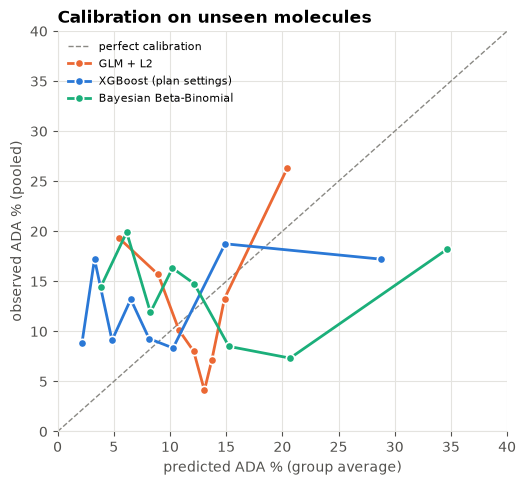

GLM + L2                 predictions span 5.4%–20.5%; observed per group span 4.1%–26.3%
XGBoost (plan settings)  predictions span 2.2%–28.8%; observed per group span 8.3%–18.8%
Bayesian Beta-Binomial   predictions span 3.8%–34.7%; observed per group span 7.3%–19.9%


In [6]:
oof = {k: pd.read_csv(RES / f"oof_{k}.csv").set_index("cohort_id").loc[df["cohort_id"], "pred"].values
       for k in ["naive", "glm_l2", "xgb_default", "bayes_betabinomial"]}

def calibration_table(pred, y, n, bins=8):
    q = pd.qcut(pred, bins, labels=False, duplicates="drop")
    t = pd.DataFrame({"q": q, "pred": pred, "y": y, "n": n})
    g = t.groupby("q").apply(lambda d: pd.Series({"mean_pred": np.average(d["pred"], weights=d["n"]),
                                                  "observed": d["y"].sum() / d["n"].sum(), "patients": d["n"].sum()}), include_groups=False)
    return g

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 40], [0, 40], color=GRAY, ls="--", lw=1, label="perfect calibration")
for k, color in [("glm_l2", ORANGE), ("xgb_default", BLUE), ("bayes_betabinomial", AQUA)]:
    g = calibration_table(oof[k], df["y"].values, df["n"].values)
    ax.plot(g["mean_pred"] * 100, g["observed"] * 100, "-o", color=color, lw=2, ms=6, mec="white", mew=1.2, label=MODELS[k])
ax.set_xlabel("predicted ADA % (group average)"); ax.set_ylabel("observed ADA % (pooled)")
lim = 40
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title("Calibration on unseen molecules"); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(ROOT / "figures" / "calibration.png"); plt.show()
for k in ["glm_l2", "xgb_default", "bayes_betabinomial"]:
    g = calibration_table(oof[k], df["y"].values, df["n"].values)
    print(f"{MODELS[k]:24s} predictions span {g.mean_pred.min():.1%}–{g.mean_pred.max():.1%}; observed per group span {g.observed.min():.1%}–{g.observed.max():.1%}")

## 4 · Honest uncertainty: predictive distributions and 90 % interval coverage

Point-prediction models (GLM, XGBoost) implicitly assume **Binomial** spread around their prediction. The Bayesian
Beta-Binomial has its own, wider predictive distribution. To compare *distributions* fairly we add one more baseline:
an **intercept-only Beta-Binomial** (one average rate + one overdispersion φ, fitted per training fold, no clues).
It answers: *once uncertainty is modelled honestly, do the clues still help?*

In [7]:
def fit_naive_bb(train):
    """Maximum-likelihood mean rate and concentration φ for a Beta-Binomial with no features."""
    y, n = train["y"].values, train["n"].values
    nll = lambda t: -betabinom.logpmf(y, n, expit(t[0]) * np.exp(t[1]), (1 - expit(t[0])) * np.exp(t[1])).sum()
    t = minimize(nll, x0=[-2.0, 1.0], method="Nelder-Mead").x
    return expit(t[0]), np.exp(t[1])

nbb = []
for k in range(5):
    tr, te = df[df.fold_grouped != k], df[df.fold_grouped == k]
    mu, phi = fit_naive_bb(tr)
    a, b = mu * phi, (1 - mu) * phi
    lo, hi = betabinom.ppf(0.05, te["n"], a, b), betabinom.ppf(0.95, te["n"], a, b)
    nbb.append(pd.DataFrame({"cohort_id": te["cohort_id"].values, "lps": betabinom.logpmf(te["y"], te["n"], a, b),
                             "lo": lo, "hi": hi, "fold": k}))
    print(f"fold {k}: naive Beta-Binomial mean = {mu:.3f}, φ = {phi:.2f}")
nbb = pd.concat(nbb).set_index("cohort_id").loc[df["cohort_id"]].reset_index()

y, n = df["y"].values, df["n"].values
rows = []
for k in ["naive", "glm_l2", "xgb_default"]:
    lo, hi = im.binomial_interval(n, np.clip(oof[k], 1e-6, 1 - 1e-6))
    inside = (y >= lo) & (y <= hi)
    rows.append({"model": MODELS[k], "predictive spread": "Binomial (implied)",
                 "mean log predictive score": binom.logpmf(y, n, np.clip(oof[k], 1e-6, 1 - 1e-6)).mean(), "90 % coverage": inside.mean()})
for label, pr in [("Naive Beta-Binomial (no clues)", nbb),
                  ("Bayesian Binomial", pd.read_csv(RES / "predictive_bayes_binomial.csv")),
                  ("Bayesian Beta-Binomial", pd.read_csv(RES / "predictive_bayes_betabinomial.csv"))]:
    inside = (y >= pr["lo"].values) & (y <= pr["hi"].values)
    rows.append({"model": label, "predictive spread": "Beta-Binomial" if "Beta" in label else "Binomial",
                 "mean log predictive score": pr["lps"].mean(), "90 % coverage": inside.mean()})
unc = pd.DataFrame(rows)
display(unc.style.format({"mean log predictive score": "{:.2f}", "90 % coverage": "{:.1%}"}).hide(axis="index"))

# paired per-fold: does the Bayesian Beta-Binomial (with clues) beat the naive Beta-Binomial on log predictive score?
pb = pd.read_csv(RES / "predictive_bayes_betabinomial.csv").assign(fold=df["fold_grouped"].values)
d = pb.groupby("fold")["lps"].mean() - nbb.groupby("fold")["lps"].mean()
print(f"\nBeta-Binomial with clues − without clues, log predictive score: {d.mean():+.3f} (fold SD {d.std():.3f}); better in {(d > 0).sum()}/5 folds")

fold 0: naive Beta-Binomial mean = 0.155, φ = 2.44
fold 1: naive Beta-Binomial mean = 0.122, φ = 2.99


fold 2: naive Beta-Binomial mean = 0.150, φ = 2.55
fold 3: naive Beta-Binomial mean = 0.139, φ = 2.61


fold 4: naive Beta-Binomial mean = 0.157, φ = 2.12


model,predictive spread,mean log predictive score,90 % coverage
Naive baseline,Binomial (implied),-17.83,49.1%
GLM + L2,Binomial (implied),-18.68,50.2%
XGBoost (plan settings),Binomial (implied),-19.78,52.6%
Naive Beta-Binomial (no clues),Beta-Binomial,-2.82,94.6%
Bayesian Binomial,Binomial,-25.73,47.0%
Bayesian Beta-Binomial,Beta-Binomial,-2.97,87.6%



Beta-Binomial with clues − without clues, log predictive score: -0.152 (fold SD 0.136); better in 0/5 folds


## 5 · Verdict (Day 13 write-up)

**1. Point prediction for a new molecule (grouped CV, mean ± fold SD):**

| model | wMAE ↓ | wRMSE ↓ | loglik ↑ | wMAE gain vs naive (folds won) |
|---|---|---|---|---|
| **Naive baseline** | 0.131 ± 0.037 | 0.183 ± 0.060 | **−17.8** ± 8.9 | (reference) |
| GLM + L2 | 0.132 ± 0.039 | 0.183 ± 0.062 | −18.7 ± 10.0 | −0.1 pts (3/5) |
| **XGBoost (plan settings)** | **0.128** ± 0.038 | **0.180** ± 0.060 | −19.8 ± 11.0 | **+0.3 pts (4/5)** |
| XGBoost + sequence (not adopted) | 0.115 ± 0.049 | 0.177 ± 0.069 | −19.9 ± 13.1 | +1.6 pts (3/5, SD 2.0) |
| Bayesian Beta-Binomial | 0.159 ± 0.034 | 0.209 ± 0.044 | −21.6 ± 10.9 | −2.7 pts (0/5) |
| GLM (plain) / Bayesian Binomial | 0.161 / 0.160 | 0.230 / 0.226 | −33.4 / −29.3 | −3.0 / −2.9 pts (0/5) |

* **Winner on point error: XGBoost (plan settings), but only by 0.3 percentage points**, which is smaller than the fold-to-fold spread of the gain (SD 0.5). It is *worse* than the naive baseline on log-likelihood. **No model convincingly beats "predict the average" for a brand-new molecule.**
* Models that trust every patient as independent (plain GLM, Bayesian Binomial) are clearly worst.

**2. Calibration:** the models spread their predictions far more widely (≈ 2–35 %) than the observed rates in those groups (≈ 4–26 %). They are **over-confident about differences between molecules**: when a model predicts a very low or very high rate for a new molecule, reality is usually closer to average. This matches the overdispersion and few-molecule story.

**3. Honest uncertainty (90 % predictive intervals on unseen molecules):**
* Every model that assumes Binomial spread (naive, GLM, XGBoost, Bayesian Binomial) covers only **47–53 %** of held-out cohorts.
* Beta-Binomial models cover **88–95 %**, close to the 90 % target.
* The **best predictive distribution** is the **intercept-only Beta-Binomial** (log predictive score −2.82, coverage 94.6 %). Adding all clues in the Bayesian Beta-Binomial is slightly worse (−2.97, 87.6 %; worse in 5/5 folds).

**Verdict.** For a new molecule, the most honest forecast from this database is roughly **"about 14 % of patients on average, with a very wide range"**. Modelling **overdispersion** correctly matters far more for honest prediction than any of the clues we have. The clues are still useful for **understanding associations** (notebook 11), where several effects are consistent across methods, but they do not translate into reliably better predictions for unseen molecules. This is the central, honestly reported result of the project.